<a href="https://colab.research.google.com/github/Laboratorio-de-Analise-de-Dados/img-PEP/blob/main/2_CHO_GTS_745_05_06_24.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Instalando biblioteca que não tem no Collab

Importação de Bibliotecas

In [1]:
import os #organizador de pasta
import numpy as np #estruturação dos dados
import matplotlib.pyplot as plt #plot gráfico
import seaborn as sns #plot gráfico
from PIL import Image #visualização de img
import pandas as pd #estruturação dos dados
from util import meus_uteis, timeProcess
import joblib #convertendo imagens em valores numéricos .gz

Salvando essas pastas de imagens em formato de pastas em formato de comando linux.

Carregando a lista de imagens:

Abrindo os arquivos:

In [2]:
link_files = './data/imagem_conjunto/CHO-745/GST/'
lista_arquivos_fluo = [link_files+i for i in os.listdir(link_files) if 'ch01' in i]
lista_arquivos_fluo

['./data/imagem_conjunto/CHO-745/GST/Experiment_CHO_745_GST_anti_v01_ch01.tif',
 './data/imagem_conjunto/CHO-745/GST/Experiment_CHO_745_GST_anti_v02_ch01.tif',
 './data/imagem_conjunto/CHO-745/GST/Experiment_CHO_745_GST_anti_v03_ch01.tif',
 './data/imagem_conjunto/CHO-745/GST/Experiment_CHO_745_GST_anti_v04_ch01.tif',
 './data/imagem_conjunto/CHO-745/GST/Experiment_CHO_745_GST_anti_v05_ch01.tif',
 './data/imagem_conjunto/CHO-745/GST/Experiment_CHO_745_GST_anti_v06_ch01.tif',
 './data/imagem_conjunto/CHO-745/GST/Experiment_CHO_745_GST_anti_v07_ch01.tif',
 './data/imagem_conjunto/CHO-745/GST/Experiment_CHO_745_GST_anti_v08_ch01.tif',
 './data/imagem_conjunto/CHO-745/GST/Experiment_CHO_745_GST_anti_v10_ch01.tif',
 './data/imagem_conjunto/CHO-745/GST/Experiment_CHO_745_GST_anti_v9_ch01.tif',
 './data/imagem_conjunto/CHO-745/GST/Experiment_CHO_745_GST_v01_ch01.tif',
 './data/imagem_conjunto/CHO-745/GST/Experiment_CHO_745_GST_v02_ch01.tif',
 './data/imagem_conjunto/CHO-745/GST/Experiment_CHO

In [3]:
len(lista_arquivos_fluo)

21

Abrindo a primeira imagem de GTS CHO 745:

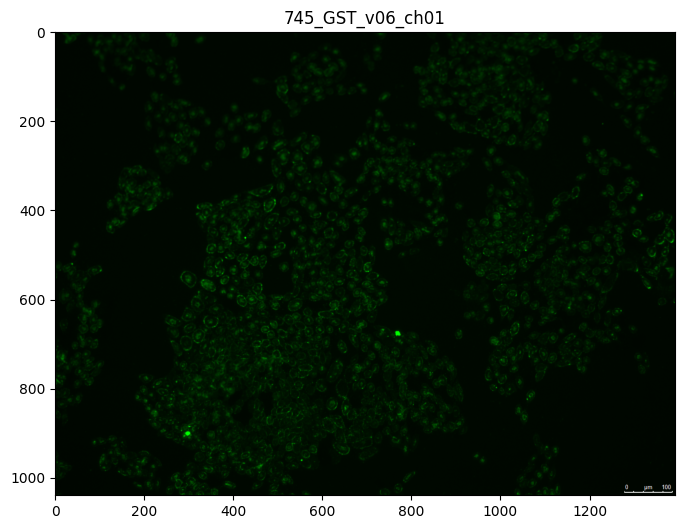

In [4]:
path = lista_arquivos_fluo[15] #chamando a primeira imagem
img = Image.open(path) #abrinado a primeira imagem

plt.figure(figsize=(8,8)) #tamanho da imagem
plt.imshow(img) #abrindo a imagem
plt.title(path[50:-4]) #título recortando o nome do título que corresponde o caminho da imagem[50:-4]
plt.show()

Convertendo a imagem escolhida para um DataFrame

In [5]:
#definindo uma função que converte as imagens em matriz numpy
def img_to_df(img) -> pd.DataFrame:
  img_array = np.array(img, dtype="float64")/255 #organizando o tamanho da matriz
  img_df = pd.DataFrame(columns=["red"], data=img_array[:,:,0].reshape(-1,1)) #aqui a cor vermelha da imagem foi anulada e os valores entraram como zero na coluna da df
  img_df["green"] = img_array[:,:,1].reshape(-1,1) # mantendo apenas a camada verde (de interesse)
  img_df["blue"] = img_array[:,:,2].reshape(-1,1) #mesma coisa que foi feita na camada vermelha foi feita com a azul

  return img_df

In [6]:
img_df_first = img_to_df(img=img) #chamando a função criada e como parâmetro está sendo passado a imagem organizada na pasta lá em cima.
img_df_first.head()

,red,green,blue
0,0.0,0.031373,0.0
1,0.0,0.027451,0.0
2,0.0,0.023529,0.0
3,0.0,0.031373,0.0
4,0.0,0.031373,0.0


#Dataframe com as imagens e valores originais

In [7]:
lista_arquivos_fluo[0].split("Experiment_")[1][:-4]

'CHO_745_GST_anti_v01_ch01'

In [8]:
img_df_orig = pd.DataFrame() #criando uma df
img_dict = {} #criando um dicionário
for path in lista_arquivos_fluo:  #laço para pasta o que tiver em lista de arquivos controle
  key = path.split("Experiment_")[1][:-4]
  img = Image.open(path)              #abrinado a imagem que contem em path
  img_df_modif = img_to_df(img=img) #retirando os outliers dos dados da df

  img_df_orig[key] = img_df_modif['green'] #renomeando a coluna com o final do nome do ar arquivo e sustituindo a coluna green

  img_dict[key] = img_df_modif

img_df_orig.head()

,CHO_745_GST_anti_v01_ch01,CHO_745_GST_anti_v02_ch01,CHO_745_GST_anti_v03_ch01,CHO_745_GST_anti_v04_ch01,CHO_745_GST_anti_v05_ch01,CHO_745_GST_anti_v06_ch01,CHO_745_GST_anti_v07_ch01,CHO_745_GST_anti_v08_ch01,CHO_745_GST_anti_v10_ch01,CHO_745_GST_anti_v9_ch01,...,CHO_745_GST_v02_ch01,CHO_745_GST_v03_ch01,CHO_745_GST_v04_ch01,CHO_745_GST_v05_ch01,CHO_745_GST_v06_ch01,CHO_745_GST_v07_ch01,CHO_745_GST_v08_ch01,CHO_745_GST_v09_ch01,CHO_745_GST_v10_ch01,CHO_745_GST_v11_ch01
0,0.027451,0.047059,0.027451,0.023529,0.027451,0.027451,0.023529,0.027451,0.027451,0.023529,...,0.027451,0.027451,0.027451,0.023529,0.031373,0.019608,0.023529,0.117647,0.023529,0.023529
1,0.035294,0.050980,0.027451,0.027451,0.023529,0.031373,0.027451,0.023529,0.019608,0.023529,...,0.023529,0.023529,0.027451,0.027451,0.027451,0.019608,0.027451,0.109804,0.023529,0.023529
2,0.027451,0.054902,0.027451,0.027451,0.027451,0.031373,0.023529,0.023529,0.023529,0.027451,...,0.027451,0.023529,0.027451,0.023529,0.023529,0.023529,0.027451,0.105882,0.023529,0.027451
3,0.027451,0.047059,0.023529,0.027451,0.027451,0.023529,0.027451,0.027451,0.023529,0.023529,...,0.023529,0.027451,0.027451,0.027451,0.031373,0.023529,0.031373,0.109804,0.027451,0.023529
4,0.031373,0.047059,0.027451,0.023529,0.027451,0.027451,0.027451,0.023529,0.027451,0.023529,...,0.027451,0.027451,0.031373,0.023529,0.031373,0.019608,0.031373,0.113725,0.023529,0.027451


Salvando a df de imagens originais

In [9]:
data = timeProcess()[1]
joblib.dump(pd.DataFrame(img_df_orig), f'{link_files}Original_dataframe-CHO745-GST-fluorescente-{data}.gz')

['./data/imagem_conjunto/CHO-745/GST/Original_dataframe-CHO745-GST-fluorescente-2026-10-16.gz']

#Criando uma função para retirada do excesso de intensidade do pixel encontrados nas imagens:

Esse código foi criada para Calcular a frequencia em qu os pixels estão presentes na imagem. Quanto mais próximo o pixel esta de 1.0, vai verde é esse ponto e é o que precisa ser corrigido na imagem.

In [ ]:
img_df_green = img_df_first['green'].copy() #copiando apenas a coluna verde da df original
freq = (
    img_df_green.value_counts(normalize=True)
    .to_frame()
    .reset_index()
    .rename(columns={'index':'green', 'green':'proportion'})
    .sort_values('green', ascending=False)
)
freq.head()

,green,proportion
65,1.000000,3.267297e-04
223,0.996078,6.907604e-07
209,0.992157,6.907604e-07
203,0.988235,6.907604e-07
226,0.980392,6.907604e-07


In [28]:
#somando os valores para ferificar se ele chegou ao valor 1.0
freq.sum()

green         108.058824
proportion      1.000000
dtype: float64

Retirando 5% da frequencia dos valores mais altos que representam a cor verde na imagem. O laço percorre do 1.0 até chegar no valor 0.05 (5%) e finaliza no valor de pixel que deve ser filtrado os valores acima ou igual a 0.05 para reduzir a intensidade de verde.

In [29]:
soma = 0 #igualando a variavel a 0
for n in range(len(freq)): #iteração para percorrer na df e somar os valores da coluna 1
  soma += freq.iloc[n,1]
  if soma >= 0.001: #5% dos dados
    print(soma)
    break
print(freq.iloc[n,:])

0.001013345490716181
green         0.427451
proportion    0.000023
Name: 110, dtype: float64


In [30]:
#criando cópia da df original e filtrando os valores da nova df
img_df_second = img_df_first.copy()

In [ ]:
#Criando função pra que receba uma df, indique qual coluna usar, o valor a ser alterado e o novo valor
def filter_and_replace(dataframe, column_name, threshold, new_value):
    """
    Filtra os valores da coluna especificada na DataFrame que sejam maiores ou iguais ao limite
    especificado e substitui-os pelo novo valor.

    Args:
        dataframe (pandas.DataFrame): A DataFrame a ser filtrada e modificada.
        column_name (str): O nome da coluna que será filtrada e modificada.
        threshold (float): O valor limite para o filtro.
        new_value (float): O novo valor a ser atribuído aos valores filtrados.

    Returns:
        pandas.DataFrame: A DataFrame modificada.
    """
    dataframe.loc[dataframe[column_name] >= threshold, column_name] = new_value
    return dataframe

In [ ]:
novo_valor = 0.0
img_df_second_filtrada = filter_and_replace(img_df_second, 'green', 0.427451, novo_valor)
img_df_second_filtrada

,red,green,blue
0,0.0,0.031373,0.0
1,0.0,0.027451,0.0
2,0.0,0.023529,0.0
3,0.0,0.031373,0.0
4,0.0,0.031373,0.0
...,...,...,...
1447675,0.0,0.023529,0.0
1447676,0.0,0.023529,0.0
1447677,0.0,0.023529,0.0
1447678,0.0,0.023529,0.0


#Plotando o boxplot com dados originais e retirada de outliers

In [ ]:
def maxplot() -> float:
  if img_df_first.max().max() > img_df_second_filtrada.max().max():
    max = img_df_first.max().max()
  else:
    max = img_df_second_filtrada.max().max()

  max_freq = max/10

  return max + max_freq

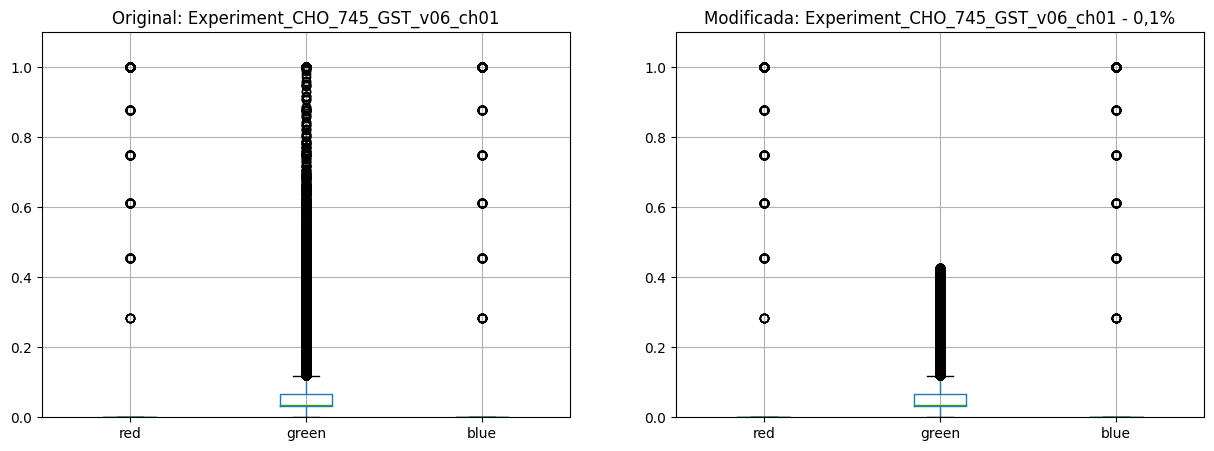

In [ ]:
plt.figure(figsize=(15,5))

plt.subplot(1, 2, 1)
plt.title(f"Original: {path[50:-4]}")
img_df_first.boxplot()
plt.ylim(0, maxplot())


plt.subplot(1, 2, 2)
plt.title(f"Modificada: {path[50:-4]} - 0,1%")
img_df_second_filtrada.boxplot()
plt.ylim(0, maxplot())

# plt.plot( #função para plotar o gráfico
#     [plot_media, plot_media], #faixa que marca a média
#     c='red' #cor vermelha da faixa
# )
# plt.plot(#função para plotar o gráfico
#     [plot_mediana,plot_mediana],
#     c='green' #cor verde da faixa
# )


plt.show()

#Imagem original e pós nivelado os píxels:

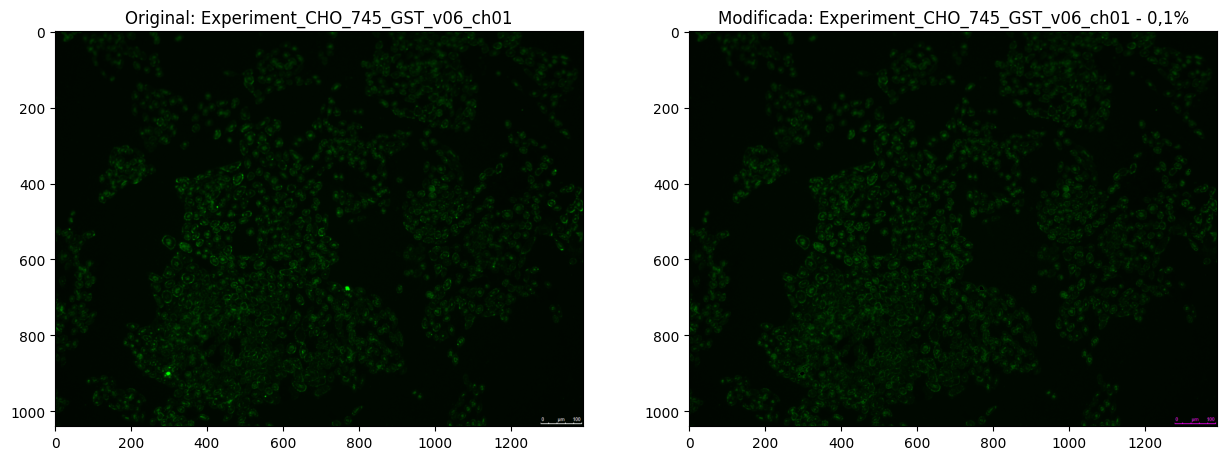

In [ ]:
plt.figure(figsize=(15,15))

plt.subplot(1, 2, 1)
plt.imshow(np.array(img_df_first).reshape(1040, 1392, 3))
plt.title(f"Original: {path[50:-4]}")

plt.subplot(1, 2, 2)
plt.imshow(np.array(img_df_second_filtrada).reshape(1040, 1392, 3))
plt.title(f"Modificada: {path[50:-4]} - 0,1%")

# plt.subplot(1, 2, 3)
# plt.imshow(np.array(img_df_copy).reshape(1040, 1392, 3))
# plt.title(f"Modificada: {path[50:-4]}")
plt.show()

#Dataframe CHO 745 proteína GTS Filtrada:

In [ ]:
img_df_gst = pd.DataFrame() #criando uma df
img_dict = {} #criando um dicionário

for path in lista_arquivos_fluo:  #laço para pasta o que tiver em lista de arquivos controle
  img = Image.open(path)              #abrinado a imagem que contem em path
  teste = filter_and_replace(img_to_df(img=img), 'green', 0.427451, novo_valor)
  img_df_gst[path[61:-4]] = teste['green'] #renomeando a coluna com o final do nome do ar arquivo e sustituindo a coluna green

  img_dict[path[67:-4]] = teste

img_df_gst.head()

,CHO_745_GST_anti_v01_ch01,CHO_745_GST_anti_v02_ch01,CHO_745_GST_anti_v03_ch01,CHO_745_GST_anti_v04_ch01,CHO_745_GST_anti_v05_ch01,CHO_745_GST_anti_v06_ch01,CHO_745_GST_anti_v07_ch01,CHO_745_GST_anti_v08_ch01,CHO_745_GST_anti_v10_ch01,CHO_745_GST_anti_v9_ch01,...,CHO_745_GST_v02_ch01,CHO_745_GST_v03_ch01,CHO_745_GST_v04_ch01,CHO_745_GST_v05_ch01,CHO_745_GST_v06_ch01,CHO_745_GST_v07_ch01,CHO_745_GST_v08_ch01,CHO_745_GST_v09_ch01,CHO_745_GST_v10_ch01,CHO_745_GST_v11_ch01
0,0.027451,0.047059,0.027451,0.023529,0.027451,0.027451,0.023529,0.027451,0.027451,0.023529,...,0.027451,0.027451,0.027451,0.023529,0.031373,0.019608,0.023529,0.117647,0.023529,0.023529
1,0.035294,0.050980,0.027451,0.027451,0.023529,0.031373,0.027451,0.023529,0.019608,0.023529,...,0.023529,0.023529,0.027451,0.027451,0.027451,0.019608,0.027451,0.109804,0.023529,0.023529
2,0.027451,0.054902,0.027451,0.027451,0.027451,0.031373,0.023529,0.023529,0.023529,0.027451,...,0.027451,0.023529,0.027451,0.023529,0.023529,0.023529,0.027451,0.105882,0.023529,0.027451
3,0.027451,0.047059,0.023529,0.027451,0.027451,0.023529,0.027451,0.027451,0.023529,0.023529,...,0.023529,0.027451,0.027451,0.027451,0.031373,0.023529,0.031373,0.109804,0.027451,0.023529
4,0.031373,0.047059,0.027451,0.023529,0.027451,0.027451,0.027451,0.023529,0.027451,0.023529,...,0.027451,0.027451,0.031373,0.023529,0.031373,0.019608,0.031373,0.113725,0.023529,0.027451


Salvando a df com os valores filtrados

In [ ]:
#salvando a df:
data = timeProcess()[1]
#joblib.dump(pd.DataFrame(img_df_gst), '/content/drive/MyDrive/teste/DataFrames pastas/DataFrames_retirada_porcentagens/1-dataframe-CHO745-GST-fluorescente-0,1%-'+data+'.gz')